# TXS 0506+056 (2017): canonical real-source workflow

Real electromagnetic data drive a five-parameter HELENA photon-SED fit: **data → 5D fit → best-fit multimessenger forward → source-resolved photons → post-fit neutrinos → Jacobian → Gauss–Newton diagnostics**. IceCube-170922A is not a Gaussian SED point and does not enter the electromagnetic likelihood. Frozen data provenance, observing windows, conversions, and row-level roles are documented in `data/PROVENANCE.md`.

> **Bethe--Heitler cache:** Run `helena cache fetch` once, then use the normal workflow. For offline/HPC storage, copy the complete validated cache and select it with `cache_dir=` or `HELENA_CACHE_DIR`. Normal forwards never download or rebuild it. See the [published-resource cache instructions](../../README.md#bethe--heitler-cache-lifecycle).

Markdown requests Times New Roman from the browser after the presentation setup; code and math retain their own fonts. Keep the shared `quickstart/notebook_markdown.css` in the repository layout. GitHub previews may ignore this styling.


In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import numpy as np
from astropy.cosmology import Planck18

example_dir = Path.cwd()
if not (example_dir / "txs0506_helpers.py").exists():
    example_dir = (Path.cwd() / "examples/txs0506_2017").resolve()
sys.path.insert(0, str(example_dir))
import txs0506_helpers as helpers
helpers.setup_notebook_style()

from helena import ModelConfig, OneZoneModel, SEDDataset, configure, fit
from helena.diagnostics import gauss_newton
from helena.sensitivity import jacobian

runtime = configure(device="auto")
runtime

mappingproxy({'requested_device': 'auto',
              'resolved_platform': 'gpu',
              'resolved_device': 'cuda:0',
              'x64': True})

## 1. Real 2017 electromagnetic data

All rows are Earth-observed $E F_E=\nu F_\nu$ in `erg cm^-2 s^-1`. The likelihood uses the Keivani Epoch-1 window (MJD 58003–58033): Swift-UVOT, Swift-XRT, NuSTAR, AGILE, Fermi-LAT and MAGIC detections plus H.E.S.S./VERITAS upper-limit constraints. Archival observations remain display-only context; excluded rows remain absent.

In [2]:
em = helpers.load_em_data(example_dir / "data/txs0506_2017_curated.csv")
usable = em["scientific_use"] != "exclude"

dataset = SEDDataset(
    energy_erg=em["energy_ev"][usable] * helpers.EV_TO_ERG,
    sed_flux_erg_cm2_s=em["sed_flux_erg_cm2_s"][usable],
    energy_error_lower_erg=em["energy_error_lower_ev"][usable] * helpers.EV_TO_ERG,
    energy_error_upper_erg=em["energy_error_upper_ev"][usable] * helpers.EV_TO_ERG,
    sed_flux_error_lower_erg_cm2_s=em["sed_flux_error_lower_erg_cm2_s"][usable],
    sed_flux_error_upper_erg_cm2_s=em["sed_flux_error_upper_erg_cm2_s"][usable],
    instrument=em["instrument"][usable],
    statistic_type=em["statistic_type"][usable],
    scientific_use=em["scientific_use"][usable],
    raw_energy_ev=em["energy_ev"][usable],
    metadata={
        "source": "TXS 0506+056, IceCube-170922A 2017 campaign",
        "selection_window": "Keivani Epoch 1, MJD 58003-58033",
        "frame": "Earth observed",
        "quantity": "E F_E = nu F_nu",
        "unit": "erg cm^-2 s^-1",
    },
)
helpers.print_dataset(em, dataset)

{'rows': 773, 'instruments': {'1SXPS(0.3-1keV)': 1, '1SXPS(0.3—10 keV)': 1, '1SXPS(1-2keV)': 1, '1SXPS(2—10 keV)': 1, '2FHL (1081GeV)': 1, '2FHL (316GeV)': 1, '2FHL (92GeV)': 1, '4XMM-DR12 (0.5-1 keV)': 2, '4XMM-DR12 (1-2 keV)': 2, '4XMM-DR12 (2-4.5 keV)': 2, '4XMM-DR12 (4.5-12 keV)': 2, 'AGILE': 1, 'ARGO2LAC': 1, 'CLASSSCAT': 1, 'ERCSC143': 1, 'ERCSC217': 1, 'Fermi 4FGL-DR3 (0.05-0.1 GeV)': 1, 'Fermi 4FGL-DR3 (0.1-0.3 GeV)': 1, 'Fermi 4FGL-DR3 (0.3-1 GeV)': 1, 'Fermi 4FGL-DR3 (1-3 GeV)': 1, 'Fermi 4FGL-DR3 (10-30 GeV)': 1, 'Fermi 4FGL-DR3 (100-1000 GeV)': 1, 'Fermi 4FGL-DR3 (3-10 GeV)': 1, 'Fermi 4FGL-DR3 (30-100 GeV)': 1, 'Fermi-LAT': 1, 'Fermi1FGL (200 Mev)': 1, 'Fermi1FGL (2Gev)': 1, 'Fermi1FGL (600 Mev)': 1, 'Fermi1FGL (60Gev)': 1, 'Fermi1FGL (6Gev)': 1, 'Fermi2FGL (200 Mev)': 1, 'Fermi2FGL (2Gev)': 1, 'Fermi2FGL (600 Mev)': 1, 'Fermi2FGL (60Gev)': 1, 'Fermi2FGL (6Gev)': 1, 'Fermi2FglLC': 22, 'Fermi3FGL (200 Mev)': 1, 'Fermi3FGL (2Gev)': 1, 'Fermi3FGL (600 Mev)': 1, 'Fermi3FGL (60

## 2. Configure HELENA

The source-informed model keeps $\delta=40$, $p_p=2$, $\gamma_{e,\max}=1.2\times10^4$, $\gamma_{p,\max}=5\times10^7$, the validated grids and all process switches fixed. The optimizer starts from the previously validated four-coordinate solution with $p_e=2$; that state is only the 5D starting point, not a downstream model curve.

In [3]:
redshift = 0.3365
luminosity_distance_cm = float(Planck18.luminosity_distance(redshift).to_value("cm"))

initial_config = ModelConfig(
    magnetic_field_G=4.125269e-1,
    radius_cm=3.277751e15,
    redshift=redshift,
    doppler_factor=40.0,
    luminosity_distance_cm=luminosity_distance_cm,
    electron_kinetic_injection_luminosity_erg_s=9.089317e41,
    electron_injection_index=2.0,
    electron_gamma_max=1.2e4,
    proton_kinetic_injection_luminosity_erg_s=1.115832e45,
    proton_injection_index=2.0,
    proton_gamma_max=5.0e7,
    enable_ssc=True,
    enable_bethe_heitler=True,
    enable_proton_proton=False,
    cold_proton_density_cm3=0.0,
    enable_pion_synchrotron_photons=True,
    enable_muon_synchrotron_photons=True,
    enable_internal_gamma_gamma=True,
    enable_ebl=True,
)

cache_dir = helpers.default_cache_dir()
initial_model = OneZoneModel(initial_config, cache_dir=cache_dir)
print(f"Bethe-Heitler cache: {cache_dir}")

Bethe-Heitler cache: [validated local BH cache]


## 3. Reproduce the accepted 5D fit

Only `log_Le`, `log_Lp`, `log_B`, `log_R`, and `p_e` are free. The unchanged mixed log-SED likelihood uses the selected EM detections and upper limits; context, excluded rows, and all neutrino quantities remain outside it.

In [4]:
fit_parameters = ["log_Le", "log_Lp", "log_B", "log_R", "p_e"]
fit_result = fit(
    initial_model,
    dataset,
    parameters=fit_parameters,
    optimizer="lbfgsb",
    options={"maxiter": 100, "ftol": 1.0e-12, "gtol": 1.0e-7},
)
assert fit_result.success, fit_result.message
assert fit_result.free_parameters == tuple(fit_parameters)

accepted = {
    "log_Le": 3.3927488775351652e41,
    "log_Lp": 3.958616711854449e45,
    "log_B": 0.24341513926374542,
    "log_R": 6.816848173943095e15,
    "p_e": 1.3654302494453847,
}
for parameter, expected in accepted.items():
    np.testing.assert_allclose(fit_result.best_parameters[parameter], expected, rtol=1.0e-8)
np.testing.assert_allclose(fit_result.nll, -7.760890107289, atol=1.0e-7)
helpers.print_fit_result(initial_config, fit_result)


Parameter  Unit       Initial          5D best fit
log_Le    erg/s       9.089317e+41    3.392749e+41
log_Lp    erg/s       1.115832e+45    3.958617e+45
log_B     G           4.125269e-01    2.434151e-01
log_R     cm          3.277751e+15    6.816848e+15
p_e                   2.000000e+00    1.365430e+00

success=True; status=0; NLL=-7.760890107288; iterations=39; evaluations=49; runtime=1363.904 s
CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


## 4. Best-fit multimessenger forward and photon components

One `ForwardResult` from `fit_result.best_config` owns every downstream photon, component, neutrino and differentiability result. Source-resolved lepton populations are evaluated after convergence with the final transport, synchrotron target and transfer state frozen. Their synchrotron and inverse-Compton mechanisms are Public escaped, EBL-attenuated Earth-frame $\nu F_\nu$ arrays. The legacy `primary_electron_ssc` alias is not plotted because its target contains every enabled synchrotron source, so the accurate label is **Primary-electron inverse Compton**.

In [5]:
best_model = OneZoneModel(fit_result.best_config, cache_dir=cache_dir)
best_result = best_model.forward()

best_photon_energy = best_result.sed["broadband_energy_earth_erg"]
best_photon_sed = best_result.sed["broadband_ebl_attenuated_energy_flux_earth_erg_cm2_s"]
component_fluxes = {
    name: best_result.components[
        f"{name}_broadband_ebl_attenuated_energy_flux_earth_erg_cm2_s"
    ]
    for name in helpers.COMPONENT_FIELDS
}

best_forward_nll = helpers.manual_log_sed_nll(em, best_photon_energy, best_photon_sed)
closure = helpers.print_component_audit(
    best_result.components, best_photon_sed, best_result.diagnostics
)
np.testing.assert_allclose(best_forward_nll, fit_result.nll, atol=1.0e-5)
assert closure < 1.0e-10
print(
    f"Direct-forward NLL={best_forward_nll:.12f}; fit NLL={fit_result.nll:.12f}; "
    f"converged={best_result.diagnostics['converged']}"
)


Escaped Earth-observed component audit
Primary $e^-$ synchrotron            peak=3.903508e-11 erg cm^-2 s^-1; max/total=9.999645e-01
Primary $e^-$ inverse Compton        peak=4.571239e-11 erg cm^-2 s^-1; max/total=9.422786e-01
BH-pair synchrotron                  peak=6.268196e-12 erg cm^-2 s^-1; max/total=6.873620e-01
BH-pair inverse Compton              peak=5.760570e-13 erg cm^-2 s^-1; max/total=4.718548e-01
Photomeson-secondary pair synchrotron peak=3.151696e-13 erg cm^-2 s^-1; max/total=1.468630e-01
Photomeson-secondary pair inverse Compton peak=2.655325e-16 erg cm^-2 s^-1; max/total=4.281590e-04
$\gamma\gamma$ reprocessed-pair synchrotron peak=7.931873e-13 erg cm^-2 s^-1; max/total=3.994834e-01
$\gamma\gamma$ reprocessed-pair inverse Compton peak=1.541533e-13 erg cm^-2 s^-1; max/total=7.402516e-02
Proton synchrotron                   peak=3.603096e-14 erg cm^-2 s^-1; max/total=1.933368e-02
$\pi^0$-decay photons                peak=9.248814e-19 erg cm^-2 s^-1; max/total=2.830742e

## 5. Post-fit neutrino prediction

The Earth-mixed all-flavour and $\nu_\mu+\bar\nu_\mu$ spectra come from the same 5D forward state. The latter is folded through the official IC86c point-source effective area at the TXS declination using the existing six-month exposure convention. This is an a posteriori consistency check, not a photon-neutrino joint likelihood or an event-level IceCube analysis.

In [6]:
neutrino_energy = best_result.neutrinos["energy_observer_erg"]
mixed_neutrinos = best_result.neutrinos["mixed_flavor_energy_flux_earth_erg_cm2_s"]
all_flavor_neutrino_sed = mixed_neutrinos["all_flavor"]
muon_neutrino_sed = mixed_neutrinos["nu_mu"] + mixed_neutrinos["anti_nu_mu"]
effective_area = helpers.load_icecube_effective_area(
    example_dir / "data/icecube_aeff_ic86c.csv"
)

expected_count = helpers.expected_events(
    neutrino_energy, muon_neutrino_sed, effective_area
)
expected_count_alert_band = helpers.expected_events(
    neutrino_energy,
    muon_neutrino_sed,
    effective_area,
    energy_range_gev=helpers.EVENT_ENERGY_RANGE_GEV,
)
probability_at_least_one = -np.expm1(-expected_count)

print(f"Six-month expected PS-selection count: {expected_count:.6g}")
print(f"Count in 183 TeV-4.3 PeV event band: {expected_count_alert_band:.6g}")
print(f"P(N >= 1): {probability_at_least_one:.6g}")

Six-month expected PS-selection count: 0.0158287
Count in 183 TeV-4.3 PeV event band: 0.00211824
P(N >= 1): 0.0157041


## 6. Broadband fit, residuals and neutrino context

Fit detections retain instrument-specific markers in both the SED and residual panels; H.E.S.S./VERITAS are explicit upper-limit constraints; the 714 archival rows are subdued context. Numerical-tail suppression below is plot-only and does not modify any model array.

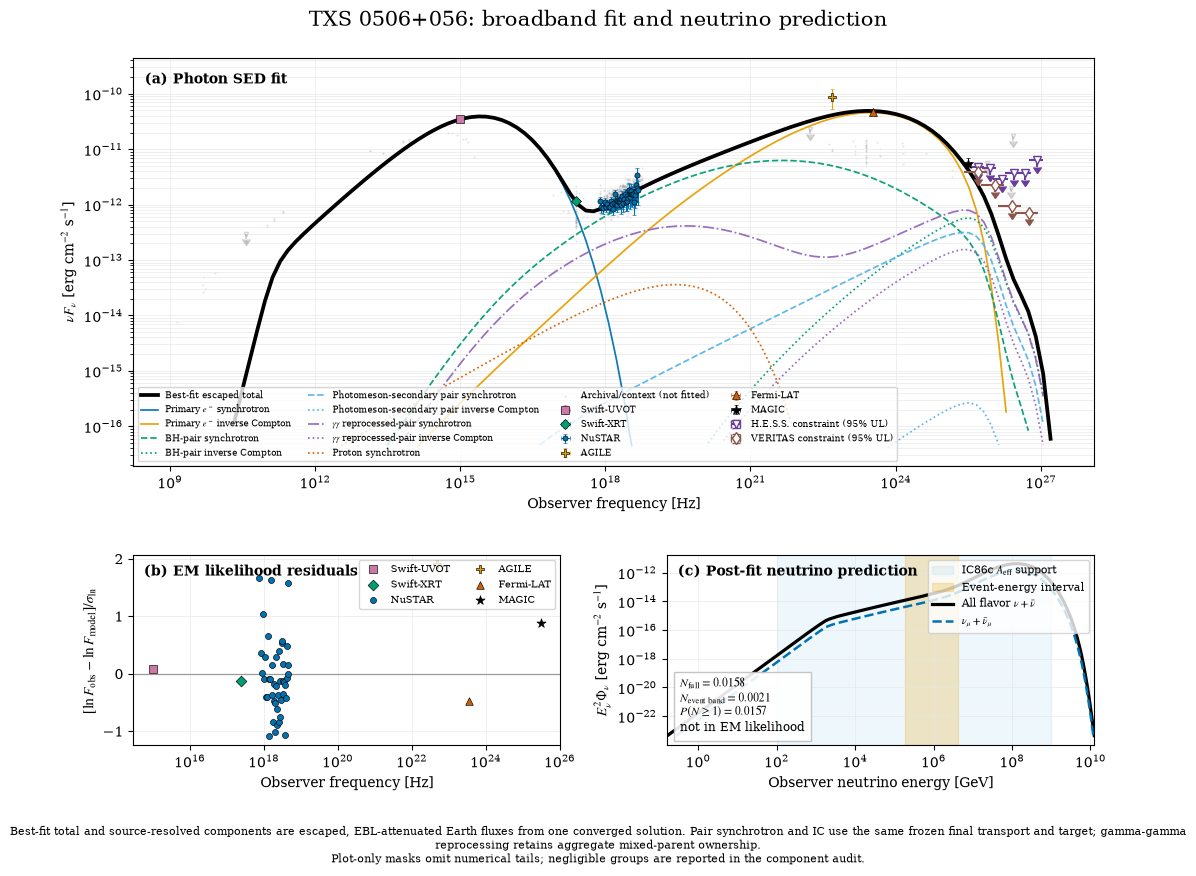

In [7]:
sed_figure = helpers.plot_broadband_fit_and_neutrino(
    em,
    best_photon_energy,
    best_photon_sed,
    best_result.components,
    neutrino_energy_erg=neutrino_energy,
    all_flavor_neutrino_sed=all_flavor_neutrino_sed,
    muon_neutrino_sed=muon_neutrino_sed,
    effective_area=effective_area,
    expected_count=expected_count,
    expected_count_alert_band=expected_count_alert_band,
    probability_at_least_one=probability_at_least_one,
)
sed_figure;

## 7. Five-dimensional broadband Jacobian

The Public Jacobian target is $\partial\ln[(E F_E^{\rm Earth})/(1\,\mathrm{erg\,cm^{-2}\,s^{-1}})]/\partial\theta$ on the model's frozen positive broadband support, in the same five-coordinate order used by the fit.

In [8]:
jacobian_result = jacobian(best_model, parameters=fit_parameters)
assert jacobian_result.parameters == tuple(fit_parameters)
assert jacobian_result.values.shape == (jacobian_result.energy_erg.size, 5)
assert np.all(np.isfinite(jacobian_result.values))
print(f"{jacobian_result.target}; shape={jacobian_result.values.shape}")

ln[(E F_E^Earth) / (1 erg cm^-2 s^-1)]; shape=(137, 5)


## 8. Gauss–Newton local identifiability

The maintained Gauss–Newton contract accepts independent symmetric Gaussian detections. We therefore use the 48 fitted detections with that published statistic for local weighting; the one asymmetric Swift-XRT detection and all upper-limit constraints remain in the 5D fit but are not silently symmetrized for this diagnostic. Gauss–Newton is local curvature at the best-fit point, not posterior covariance or global uncertainty.

Jacobian target: ln[(E F_E^Earth) / (1 erg cm^-2 s^-1)]
Jacobian shape: (137, 5)
GN status/rank: locally_identifiable/5
GN condition number: 1.374867e+02
GN singular values: [74.552776 25.103934 11.132441  2.334361  0.542255]
Strongest correlations: log_Lp-log_B=-0.998; log_B-log_R=-0.994; log_Lp-log_R=+0.991
Gauss-Newton is a local identifiability diagnostic at the 5D best-fit point, not a posterior covariance or global uncertainty estimate.


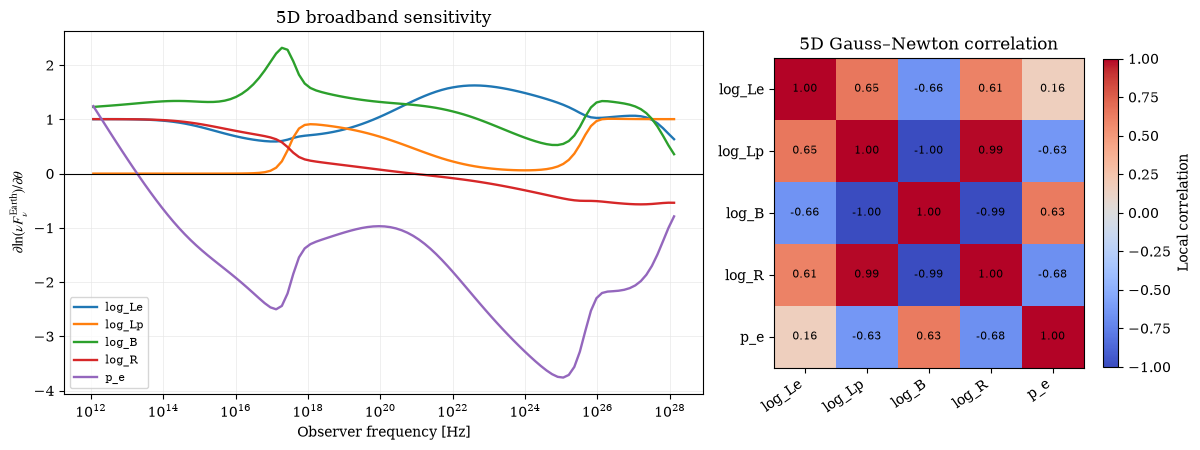

In [9]:
gn_mask = (em["scientific_use"] == "fit") & (em["statistic_type"] == "gaussian")
gn_dataset = SEDDataset(
    energy_erg=em["energy_ev"][gn_mask] * helpers.EV_TO_ERG,
    sed_flux_erg_cm2_s=em["sed_flux_erg_cm2_s"][gn_mask],
    energy_error_lower_erg=em["energy_error_lower_ev"][gn_mask] * helpers.EV_TO_ERG,
    energy_error_upper_erg=em["energy_error_upper_ev"][gn_mask] * helpers.EV_TO_ERG,
    sed_flux_error_lower_erg_cm2_s=em["sed_flux_error_lower_erg_cm2_s"][gn_mask],
    sed_flux_error_upper_erg_cm2_s=em["sed_flux_error_upper_erg_cm2_s"][gn_mask],
    instrument=em["instrument"][gn_mask],
    statistic_type=em["statistic_type"][gn_mask],
    scientific_use=np.full(np.count_nonzero(gn_mask), "fit"),
    raw_energy_ev=em["energy_ev"][gn_mask],
    metadata={"purpose": "local Gauss-Newton weighting only"},
)
assert gn_dataset.selected_count == 48
gauss_newton_result = gauss_newton(jacobian_result, gn_dataset)
helpers.print_gauss_newton_summary(jacobian_result, gauss_newton_result)
local_diagnostics_figure = helpers.plot_local_diagnostics(
    jacobian_result, gauss_newton_result
)
local_diagnostics_figure;

### Statistical boundary

The selected real EM measurements alone determine the fit. Dense archival rows are context, and incompatible rows are explicit excludes. The neutrino SED and IceCube count are post-fit predictions. Photon components are an exactly-once post-convergence decomposition of the accepted 5D solution; $\gamma\gamma$ pairs retain aggregate mixed-parent ancestry even though their synchrotron and inverse-Compton mechanisms are shown separately.